# Median Household Income by ZIP: Feature Build

Join Census ACS median household income onto the prepared Chicago Dwellsy listings and check the result before modeling.

**Data:** real (Dwellsy) + Census ACS 5-year, table B19013_001E (by ZCTA)

**Inputs:** `chicago_prepared_full.csv`, `data/external/acs_2024_median_income_zcta.json`

**Outputs:** `data/processed/chicago_income_enriched.csv`, figures in `outputs/income/`

**Run after:** `notebooks/phase_01_market_rent/02_data_preparation.ipynb`

**Caveats**

- ACS is a single 2020-2024 snapshot applied to listings from 2020-2026, so income does not vary within a ZIP over time.
- ZIP codes and ZCTAs are not the same thing. ZIPs with no matching ZCTA (for example PO-box ZIPs) get no income.
- Incomes of 250,001 are top-coded ("250,000 or more"); Census suppression codes are set to missing.

In [8]:
%pip install matplotlib pandas numpy scikit-learn


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
seed = 710
ACS_FILE = None   # None uses data/external/acs_2024_median_income_zcta.json

In [10]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "libs").is_dir())
sys.path.insert(0, str(ROOT))          # shared libs/ package
sys.path.insert(0, str(Path.cwd()))    # income.py and rent_models.py in this folder

from libs import paths
import income, rent_models

## 1. Load listings and income

In [11]:
df = pd.read_csv(
    paths.PROCESSED / "chicago_prepared_full.csv",
    dtype={"address_zip": "string"},
    parse_dates=["creation_time"],
    low_memory=False,
)
acs = income.load_income_by_zip(ACS_FILE or income.DEFAULT_ACS_FILE)

print("Listings:", df.shape)
print("ACS ZCTAs:", len(acs), "| with a usable income:", acs[income.INCOME_COLUMN].notna().sum())
display(acs.describe())

Listings: (545312, 49)
ACS ZCTAs: 33772 | with a usable income: 30547


,median_hh_income
count,30547.000000
mean,78685.723999
std,33365.493084
min,2499.000000
25%,57505.000000
50%,72067.000000
75%,91997.500000
max,250001.000000


## 2. Join and check coverage

In [12]:
enriched = income.add_income(df, acs)
coverage = income.coverage_report(enriched)
display(coverage.to_frame("value"))

unmatched = (
    enriched.loc[enriched[income.MISSING_FLAG] == 1, "address_zip"]
    .value_counts(dropna=False)
    .head(15)
)
print("Most common ZIPs with no income:")
display(unmatched.to_frame("listings"))

,value
listings,545312.000000
listings_with_income_pct,100.000000
distinct_zips,380.000000
zips_with_income_pct,100.000000
listings_top_coded_pct,0.212539


Most common ZIPs with no income:


,listings
address_zip,


Missing income is kept as missing (the models impute it with the training median) and an `income_missing` flag is carried along so a model can tell imputed values from real ones.

## 3. Does income line up with rent?

ZIPs with at least 20 listings: 327
Spearman correlation, ZIP income vs ZIP median rent: 0.683


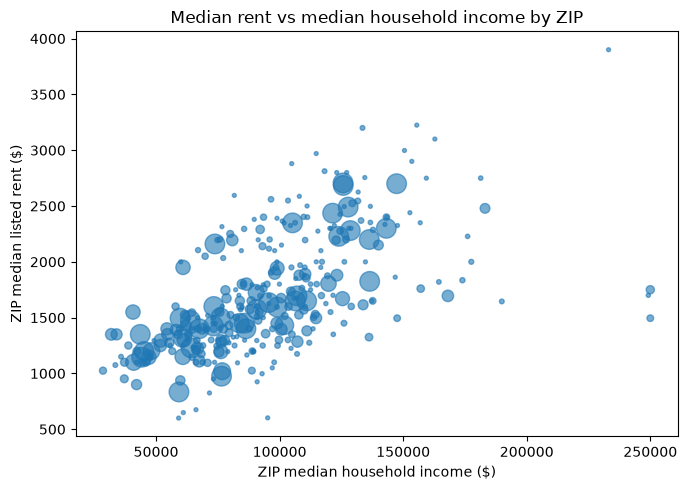

In [13]:
zip_level = (
    enriched.dropna(subset=[income.INCOME_COLUMN])
    .groupby("address_zip")
    .agg(median_rent=("rent_amount", "median"),
         income=(income.INCOME_COLUMN, "first"),
         listings=("rent_amount", "size"))
    .query("listings >= 20")
)

print("ZIPs with at least 20 listings:", len(zip_level))
print("Spearman correlation, ZIP income vs ZIP median rent:",
      round(zip_level["income"].corr(zip_level["median_rent"], method="spearman"), 3))

out_dir = paths.output_dir() / "income"
out_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(zip_level["income"], zip_level["median_rent"],
           s=np.clip(zip_level["listings"] / 20, 8, 200), alpha=0.6)
ax.set_xlabel("ZIP median household income ($)")
ax.set_ylabel("ZIP median listed rent ($)")
ax.set_title("Median rent vs median household income by ZIP")
fig.tight_layout()
fig.savefig(out_dir / "income_vs_rent_by_zip.png", dpi=150)
plt.show()

In [14]:
# Within-bedroom check: does the income-rent link survive controlling for unit size?
bed = enriched.dropna(subset=[income.INCOME_COLUMN, "bedrooms"]).copy()
bed["income_quartile"] = pd.qcut(bed[income.INCOME_COLUMN], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
display(
    bed[bed["bedrooms"].between(0, 3)]
    .pivot_table(index="income_quartile", columns="bedrooms",
                 values="rent_amount", aggfunc="median", observed=True)
    .round(0)
)

bedrooms,0,1,2,3
income_quartile,,,,
Q1 low,1010.0,1200.0,1385.0,1620.0
Q2,1075.0,1357.0,1650.0,2195.0
Q3,1347.0,1710.0,2195.0,2600.0
Q4 high,1839.0,2180.0,2800.0,3115.0


## 4. Save the enriched dataset

In [15]:
enriched_path = paths.PROCESSED / "chicago_income_enriched.csv"
enriched.to_csv(enriched_path, index=False)
print("Saved", enriched_path, enriched.shape)

Saved /Users/shikhamehtaaa/Downloads/From-Listings-to-Intelligence/real/data/processed/chicago_income_enriched.csv (545312, 51)
